<a href="https://colab.research.google.com/github/Clasico-Insights/historico-clasicos/blob/main/02_mapa_de_tiros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Celda 1: instalar mplsoccer, conectar Drive y crear carpetas
!pip install -q mplsoccer

from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import matplotlib.pyplot as plt
import mplsoccer

BASE = '/content/drive/MyDrive/Historico_Clasicos'
os.makedirs(f'{BASE}/graficos', exist_ok=True)   # aquí guardaremos los PNG
os.makedirs(f'{BASE}/estilo', exist_ok=True)     # fuentes y logo

print('mplsoccer', mplsoccer.__version__)
print(sorted(os.listdir(BASE)))

Mounted at /content/drive
mplsoccer 1.8.1
['datos', 'estilo', 'graficos', 'inventario_clasicos_statsbomb.csv']


In [3]:
# Celda 2: estilo del proyecto (fuente, logo y colores)
import urllib.request
from matplotlib import font_manager as fm

ESTILO = f'{BASE}/estilo'
descargas = {
    'Roboto-Regular.ttf': 'https://raw.githubusercontent.com/googlefonts/roboto/main/src/hinted/Roboto-Regular.ttf',
    'Roboto-Bold.ttf':    'https://raw.githubusercontent.com/googlefonts/roboto/main/src/hinted/Roboto-Bold.ttf',
    'statsbomb_logo.png': 'https://raw.githubusercontent.com/statsbomb/open-data/master/img/SB%20-%20Icon%20Lockup%20-%20Colour%20positive.png',
}
for nombre, url in descargas.items():
    ruta = f'{ESTILO}/{nombre}'
    if not os.path.exists(ruta):          # solo descarga si no está ya en Drive
        urllib.request.urlretrieve(url, ruta)
    print(nombre, round(os.path.getsize(ruta) / 1024), 'KB')

# Registrar la fuente para que matplotlib la use en todos los gráficos
for f in ['Roboto-Regular.ttf', 'Roboto-Bold.ttf']:
    fm.fontManager.addfont(f'{ESTILO}/{f}')
plt.rcParams['font.family'] = 'Roboto'

# Colores del proyecto (los mismos en todos los posts)
FONDO  = '#14171F'   # casi negro
TEXTO  = '#F2F2F2'   # blanco roto
GRIS   = '#9AA3B2'   # textos secundarios
LINEAS = '#3A4150'   # líneas del campo
COLORES = {'Barcelona': '#E0245E', 'Real Madrid': '#F2F2F2'}

print('Fuente:', plt.rcParams['font.family'])

Roboto-Regular.ttf 503 KB
Roboto-Bold.ttf 502 KB
statsbomb_logo.png 118 KB
Fuente: ['Roboto']


In [4]:
# Celda 3: cargar el 5-0 (match_id 69299) y resumir los tiros
MATCH_ID = 69299
ev = pd.read_parquet(f'{BASE}/datos/statsbomb/eventos/{MATCH_ID}.parquet')

tiros = ev[ev['type'] == 'Shot'].copy()
tiros['x'] = tiros['location'].apply(lambda l: l[0])   # posición del tiro en el campo
tiros['y'] = tiros['location'].apply(lambda l: l[1])
tiros['gol'] = tiros['shot_outcome'] == 'Goal'

resumen = (tiros.groupby('team')
           .agg(tiros=('id', 'size'), goles=('gol', 'sum'), xg=('shot_statsbomb_xg', 'sum'))
           .round(2))
print('Eventos del partido:', len(ev))
print(resumen)

Eventos del partido: 3975
             tiros  goles    xg
team                           
Barcelona       14      5  2.77
Real Madrid      5      0  0.13


In [5]:
# Celda 4: función del mapa de tiros (plantilla reutilizable)
from mplsoccer import Pitch
from matplotlib.patches import FancyBboxPatch

def num(v):
    """2.77 -> '2,77' (coma decimal en español)"""
    return f'{v:.2f}'.replace('.', ',')

def mapa_de_tiros(tiros, equipo_izq, titulo, subtitulo, archivo):
    t = tiros.copy()
    # El equipo de la izquierda ataca hacia la izquierda: giramos sus coordenadas
    izq = t['team'] == equipo_izq
    t.loc[izq, 'x'] = 120 - t.loc[izq, 'x']
    t.loc[izq, 'y'] = 80 - t.loc[izq, 'y']

    pitch = Pitch(pitch_type='statsbomb', pitch_color=FONDO, line_color=LINEAS,
                  linewidth=1.5, pad_top=6, pad_bottom=1, pad_left=1, pad_right=1)
    fig = plt.figure(figsize=(16, 9))          # 1600 x 900 px
    fig.set_facecolor(FONDO)
    ax = fig.add_axes([0.04, 0.09, 0.92, 0.74])
    pitch.draw(ax=ax)

    for equipo, color in COLORES.items():
        te = t[t['team'] == equipo]
        for es_gol in [False, True]:
            tt = te[te['gol'] == es_gol]
            pitch.scatter(tt['x'], tt['y'], s=tt['shot_statsbomb_xg'] * 1800 + 60, ax=ax,
                          facecolors=color if es_gol else 'none', edgecolors=color,
                          linewidths=1.5 if es_gol else 2, alpha=0.9, zorder=3)
        # Resumen del equipo encima de su mitad del campo
        x_texto = 30 if equipo == equipo_izq else 90
        ax.text(x_texto, -3, f"{equipo}  {len(te)} tiros · {te['gol'].sum()} goles · "
                f"{num(te['shot_statsbomb_xg'].sum())} xG",
                ha='center', fontsize=17, fontweight='bold', color=color)

    fig.text(0.04, 0.93, titulo, fontsize=28, fontweight='bold', color=TEXTO)
    fig.text(0.04, 0.875, subtitulo, fontsize=17, color=GRIS)
    fig.text(0.04, 0.065, 'Círculo relleno = gol · Tamaño = xG del tiro '
             '(probabilidad de gol según StatsBomb)', fontsize=13, color=GRIS)
    fig.text(0.04, 0.035, 'Datos: StatsBomb Open Data', fontsize=13, color=GRIS)
    # Logo oficial de StatsBomb sobre una placa clara (el logo es para fondo claro)

    logo = plt.imread(f'{ESTILO}/statsbomb_logo.png')
    ax_logo = fig.add_axes([0.80, 0.025, 0.16, 0.05])
    ax_logo.set_zorder(1)
    ax_logo.imshow(logo)
    ax_logo.axis('off')

    fig.savefig(archivo, dpi=100, facecolor=FONDO)
    plt.show()
    print('Guardado en', archivo)

print('Función mapa_de_tiros lista')

Función mapa_de_tiros lista


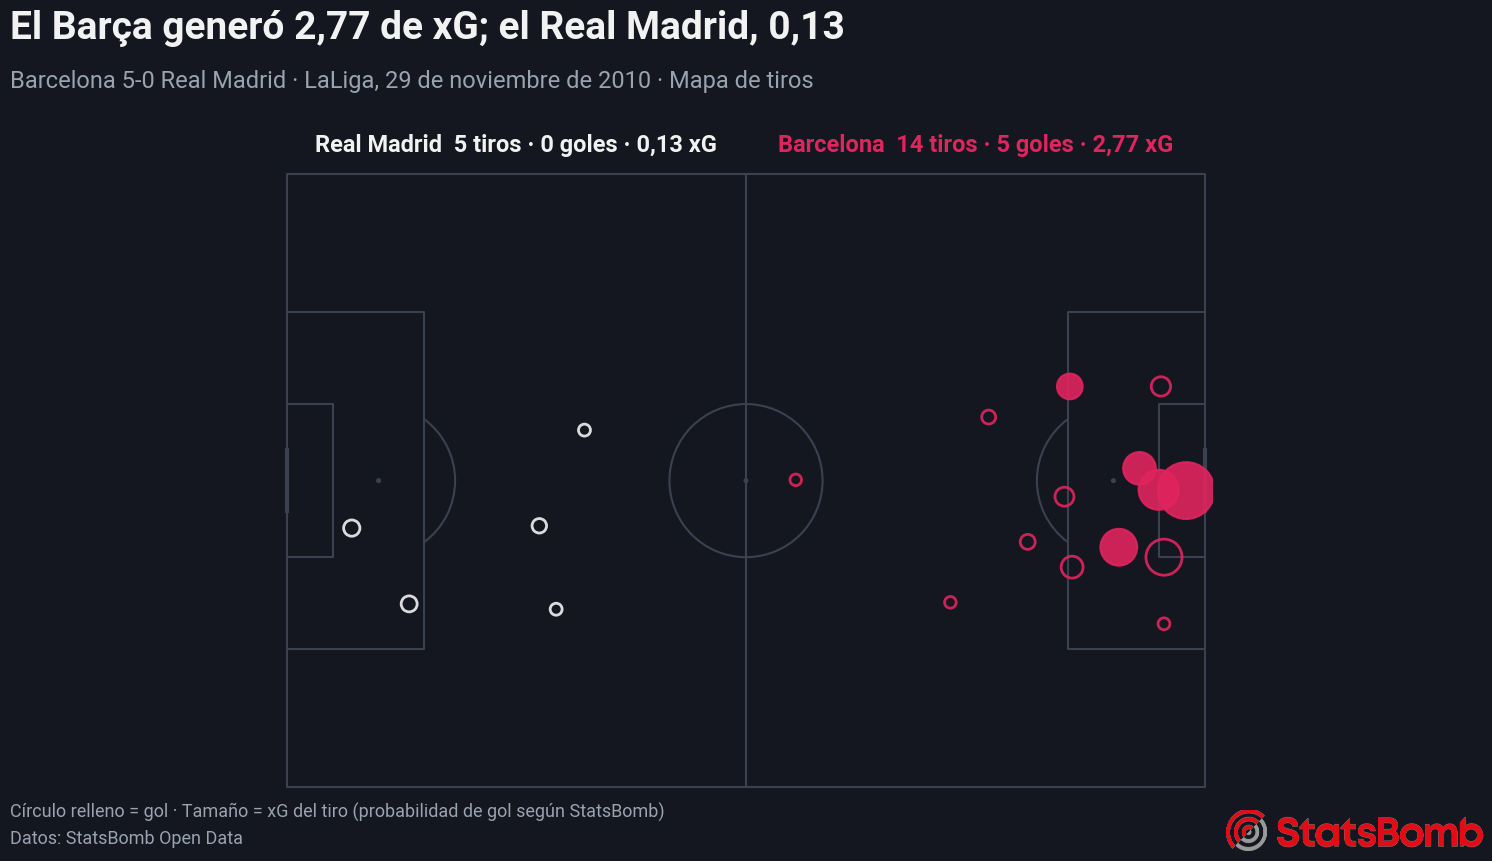

Guardado en /content/drive/MyDrive/Historico_Clasicos/graficos/2010-11-29_5-0_mapa_tiros.png


In [6]:
# Celda 5: dibujar el 5-0 y guardarlo en Drive
xg_bar = tiros.loc[tiros['team'] == 'Barcelona', 'shot_statsbomb_xg'].sum()
xg_rma = tiros.loc[tiros['team'] == 'Real Madrid', 'shot_statsbomb_xg'].sum()

mapa_de_tiros(
    tiros,
    equipo_izq='Real Madrid',
    titulo=f'El Barça generó {num(xg_bar)} de xG; el Real Madrid, {num(xg_rma)}',
    subtitulo='Barcelona 5-0 Real Madrid · LaLiga, 29 de noviembre de 2010 · Mapa de tiros',
    archivo=f'{BASE}/graficos/2010-11-29_5-0_mapa_tiros.png',
)

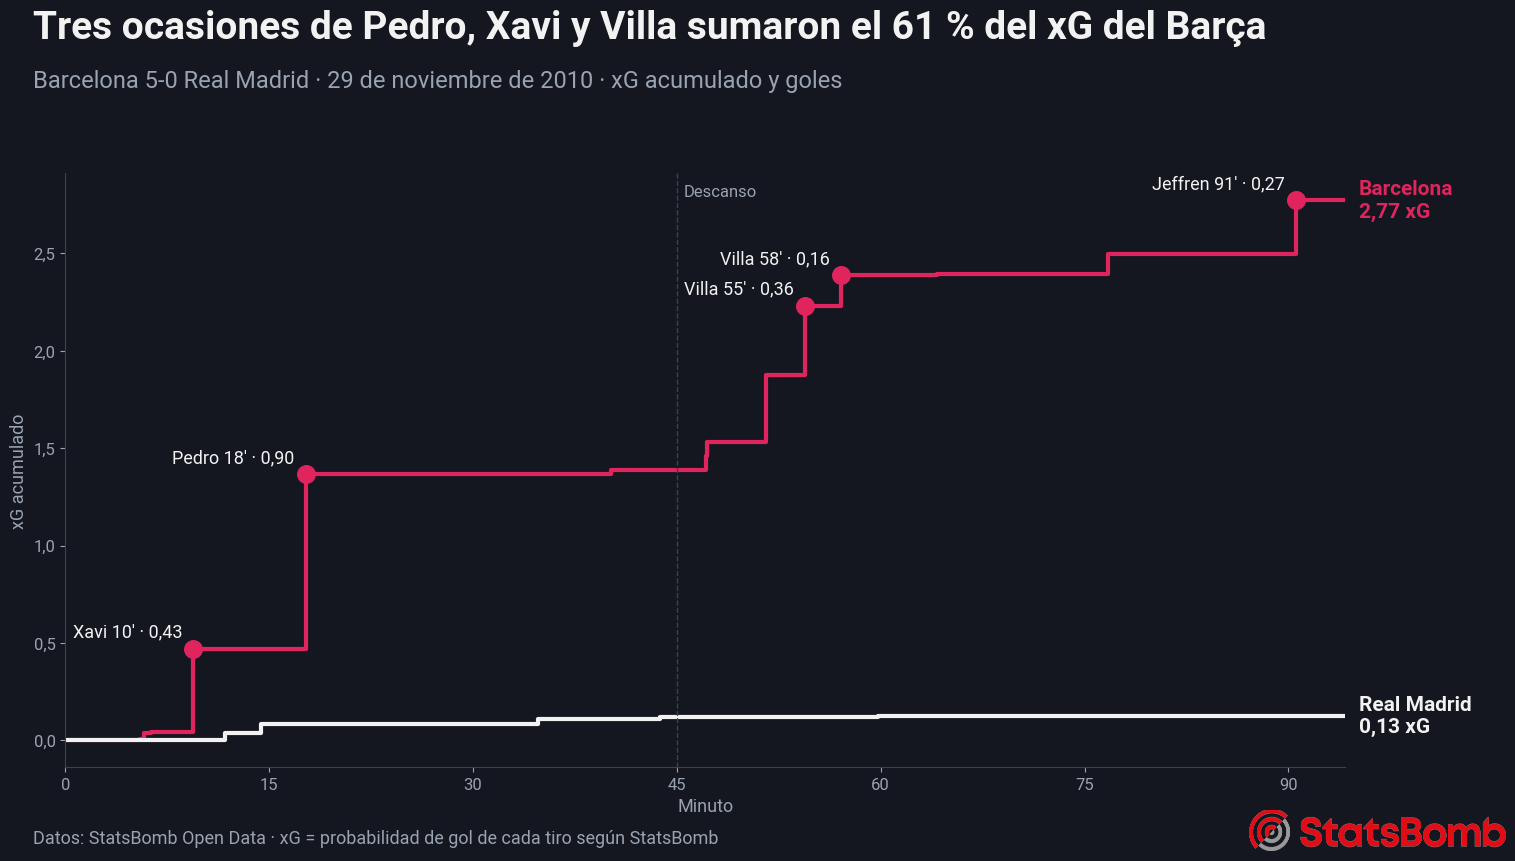

Guardado en /content/drive/MyDrive/Historico_Clasicos/graficos/2010-11-29_5-0_carrera_xg.png


In [12]:
# Celda 6: carrera de xG (xG acumulado minuto a minuto)
def carrera_xg(ev, titulo, subtitulo, archivo):
    t = ev[ev['type'] == 'Shot'].copy()
    t['min'] = t['minute'] + t['second'] / 60          # minuto con decimales
    fin = (ev['minute'] + ev['second'] / 60).max()     # último instante del partido

    fig = plt.figure(figsize=(16, 9))
    fig.set_facecolor(FONDO)
    ax = fig.add_axes([0.06, 0.12, 0.80, 0.66])
    ax.set_facecolor(FONDO)

    for equipo, color in COLORES.items():
        te = t[t['team'] == equipo].sort_values('min')
        x = [0] + te['min'].tolist() + [fin]
        y = [0] + te['shot_statsbomb_xg'].cumsum().tolist()
        y = y + [y[-1]]
        ax.step(x, y, where='post', color=color, linewidth=3)
        ax.text(fin + 1, y[-1], f'{equipo}\n{num(y[-1])} xG', color=color,
                fontsize=15, fontweight='bold', va='center')
        # Goles: punto en la línea + nombre del goleador
        acum = te['shot_statsbomb_xg'].cumsum()
        for (_, r), yy in zip(te.iterrows(), acum):
            if r['shot_outcome'] == 'Goal':
                ax.scatter(r['min'], yy, s=160, color=color, zorder=3)
                apellido = {'Xavier Hernández Creus': 'Xavi', 'Pedro Eliezer Rodríguez Ledesma': 'Pedro',
                            'David Villa Sánchez': 'Villa',
                            'Jeffren Isaac Suárez Bermúdez': 'Jeffren'}.get(r['player'], r['player'])
                ax.text(r['min'] - 0.8, yy + 0.06, f"{apellido} {r['minute'] + 1}' · {num(r['shot_statsbomb_xg'])}", color=TEXTO,
                        fontsize=13, ha='right')

    ax.axvline(45, color=LINEAS, linewidth=1, linestyle='--')
    ax.text(45.5, ax.get_ylim()[1] * 0.98, 'Descanso', color=GRIS, fontsize=12, va='top')
    ax.set_xlim(0, fin)
    ax.set_xticks([0, 15, 30, 45, 60, 75, 90])
    ax.set_xlabel('Minuto', color=GRIS, fontsize=13)
    ax.set_ylabel('xG acumulado', color=GRIS, fontsize=13)
    ax.tick_params(colors=GRIS, labelsize=12)
    ax.yaxis.set_major_formatter(lambda v, pos: f'{v:.1f}'.replace('.', ','))  # coma decimal
    for lado in ['top', 'right']:
        ax.spines[lado].set_visible(False)
    for lado in ['left', 'bottom']:
        ax.spines[lado].set_color(LINEAS)

    fig.text(0.04, 0.93, titulo, fontsize=28, fontweight='bold', color=TEXTO)
    fig.text(0.04, 0.875, subtitulo, fontsize=17, color=GRIS)
    fig.text(0.04, 0.035, 'Datos: StatsBomb Open Data · xG = probabilidad de gol de cada tiro según StatsBomb',
             fontsize=13, color=GRIS)
    logo = plt.imread(f'{ESTILO}/statsbomb_logo.png')
    ax_logo = fig.add_axes([0.80, 0.025, 0.16, 0.05])
    ax_logo.imshow(logo)
    ax_logo.axis('off')

    fig.savefig(archivo, dpi=100, facecolor=FONDO)
    plt.show()
    print('Guardado en', archivo)

carrera_xg(
    ev,
    titulo='Tres ocasiones de Pedro, Xavi y Villa sumaron el 61 % del xG del Barça',
    subtitulo='Barcelona 5-0 Real Madrid · 29 de noviembre de 2010 · xG acumulado y goles',
    archivo=f'{BASE}/graficos/2010-11-29_5-0_carrera_xg.png',
)

In [8]:
# Celda 7: ¿qué probabilidad había de marcar 5 goles con esos tiros?
import numpy as np

xg_barca = tiros.loc[tiros['team'] == 'Barcelona', 'shot_statsbomb_xg'].values
print('Tiros del Barça:', len(xg_barca), '· xG total:', round(xg_barca.sum(), 2))

# Simulamos el partido 100.000 veces: cada tiro es gol si sale un número
# aleatorio (entre 0 y 1) menor que su xG
rng = np.random.default_rng(29112010)
goles = (rng.random((100_000, len(xg_barca))) < xg_barca).sum(axis=1)

reparto = pd.Series(goles).value_counts(normalize=True).sort_index().mul(100).round(1)
print(reparto)
print('Marcar 5 o más:', round((goles >= 5).mean() * 100, 1), '%')

Tiros del Barça: 14 · xG total: 2.77
0     1.1
1    12.6
2    29.3
3    31.1
4    18.1
5     6.2
6     1.3
7     0.2
8     0.0
Name: proportion, dtype: float64
Marcar 5 o más: 7.8 %
